# Brain tumor MRI classification

Code from the original project notebook (run on Google Colab with a GPU). The scripts in this repository (`train.py`, `evaluate.py`, `gradcam.py`, `brain_tumor/`) contain the same steps; see the README.

Extra packages for the notebook: `pip install grad-cam kagglehub onnx onnxscript`.

## Data

In [ ]:
import kagglehub
import os

# Download latest version of dataset
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)
print("Folders in dataset:", os.listdir(path))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset
Folders in dataset: ['Training', 'Testing']


### One example per class

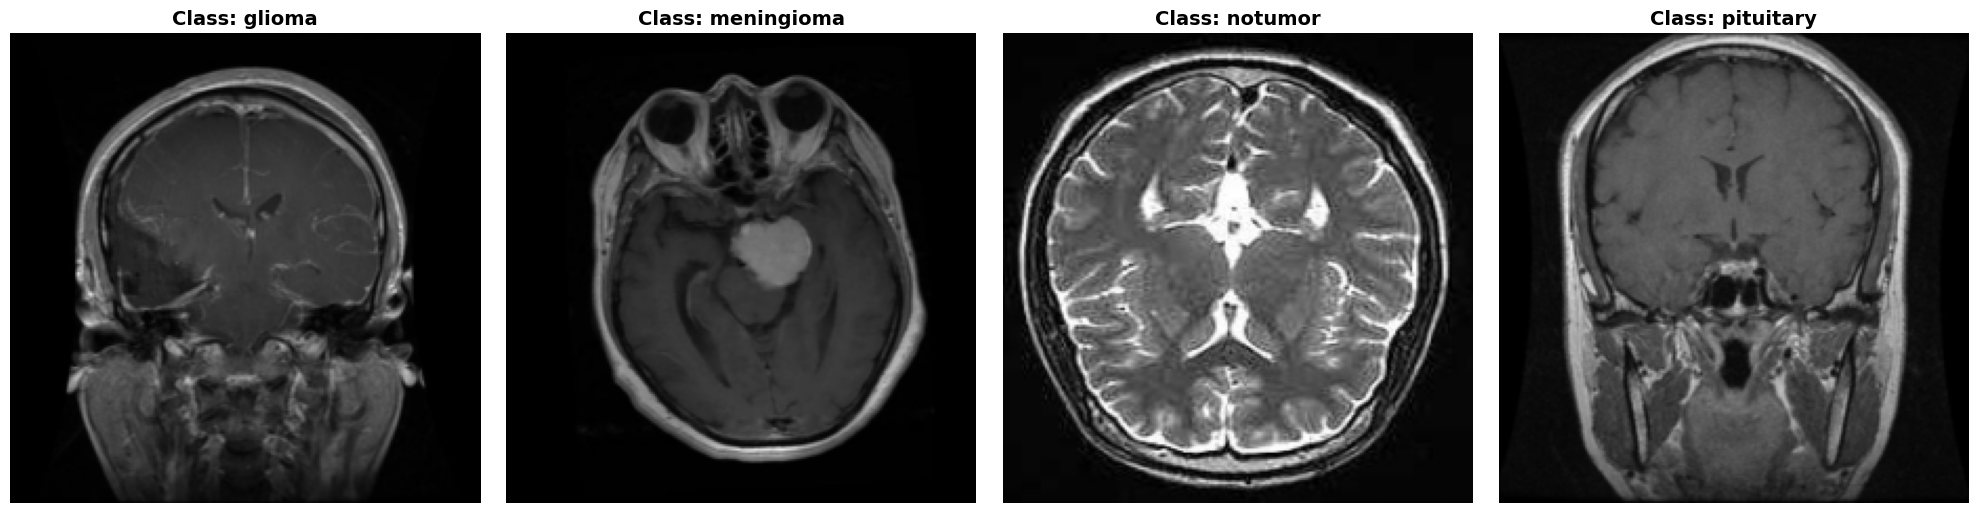

In [ ]:
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Simple transform for visualization
viz_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Load the training set
# Note: Ensure os.path.join points to the correct 'Training' folder
train_path = os.path.join(path, 'Training')
dataset = datasets.ImageFolder(root=train_path, transform=viz_transform)

# Get class names from folder names
class_names = dataset.classes

# Find one example of each class
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
displayed_classes = []

for img, label in dataset:
    class_name = class_names[label]
    if class_name not in displayed_classes:
        idx = len(displayed_classes)

        # Convert tensor to numpy for plotting (C, H, W -> H, W, C)
        img_np = img.permute(1, 2, 0).numpy()

        axes[idx].imshow(img_np)
        axes[idx].set_title(f"Class: {class_name}", fontsize=14, fontweight='bold')
        axes[idx].axis('off')

        displayed_classes.append(class_name)

    if len(displayed_classes) == 4:
        break

plt.tight_layout()
plt.show()

### Train/validation split

In [ ]:
import torch
from torch.utils.data import random_split

# 1. Calculate the number of images for each split
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

# 2. Perform the split
# Using a manual_seed(42) ensures you get the same split every time you run the cell
train_subset, val_subset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# 3. Create DataLoaders to handle batching
train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=32, shuffle=False)

print(f"Total training folder images: {len(dataset)}")
print(f"Split into -> Training: {len(train_subset)} | Validation: {len(val_subset)}")

Total training folder images: 5600
Split into -> Training: 4480 | Validation: 1120


### Augmentation and normalization

In [ ]:
# Training: Resize + Augment + Normalize
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    # No ToTensor() here if the dataset already has it,
    # but we will handle that in the wrapper below.
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation: Resize + Normalize only
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
class ApplyTransform(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

# Wrap the subsets
train_data = ApplyTransform(train_subset, transform=train_transform)
val_data = ApplyTransform(val_subset, transform=val_transform)

# Update DataLoaders with the transformed data
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)

print("Preprocessing Applied Successfully.")

Preprocessing Applied Successfully.


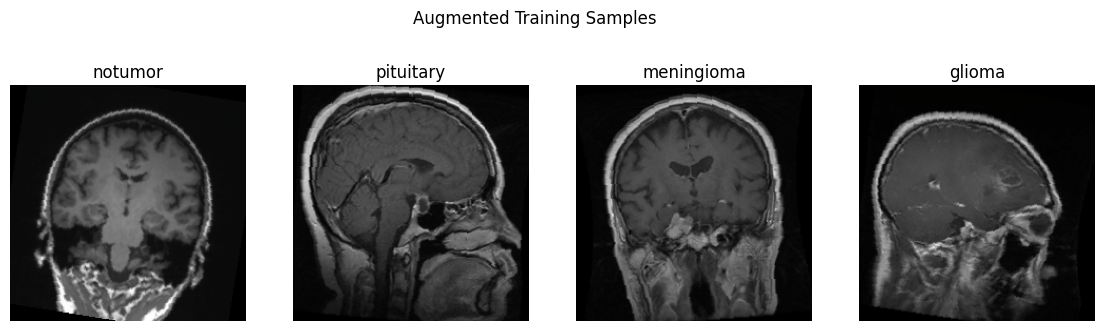

In [ ]:
import numpy as np

def show_batch(loader, title):
    images, labels = next(iter(loader))
    plt.figure(figsize=(14, 4))
    for i in range(4):
        plt.subplot(1, 4, i+1)
        # Un-normalize for visualization
        img = images[i].numpy().transpose((1, 2, 0))
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        plt.imshow(np.clip(img, 0, 1))
        plt.title(dataset.classes[labels[i]])
        plt.axis('off')
    plt.suptitle(title)
    plt.show()

show_batch(train_loader, "Augmented Training Samples")


## Custom CNN

In [ ]:
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Define the CNN Architecture (Mirroring the Keras Sequential Model)
class BrainTumorCNN(nn.Module):
    def __init__(self):
        super(BrainTumorCNN, self).__init__()

        # Block 1: Conv2D(32) -> ReLU -> MaxPooling2D(2,2)
        # Using padding=1 to keep spatial dimensions easy to calculate
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 2: Conv2D(64) -> ReLU -> MaxPooling2D(2,2)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 3: Conv2D(128) -> ReLU -> MaxPooling2D(2,2)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.flatten = nn.Flatten()

        # Calculate Flatten size:
        # 224x224 -> pool1(112x112) -> pool2(56x56) -> pool3(28x28)
        # 128 channels * 28 * 28 = 100352
        self.fc1 = nn.Linear(128 * 28 * 28, 128)
        self.relu4 = nn.ReLU()

        # Output Layer: 4 classes.
        # Note: PyTorch's CrossEntropyLoss handles the Softmax internally, so we output raw logits.
        self.fc2 = nn.Linear(128, 4)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.pool3(self.relu3(self.conv3(x)))
        x = self.flatten(x)
        x = self.relu4(self.fc1(x))
        x = self.fc2(x)
        return x


In [ ]:
#Setup Device, Model, Optimizer, and Loss
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = BrainTumorCNN().to(device)
criterion = nn.CrossEntropyLoss() # Equivalant to 'sparse_categorical_crossentropy'
optimizer = optim.Adam(model.parameters())


Using device: cuda


In [ ]:
import copy
from torch.optim.lr_scheduler import ReduceLROnPlateau
from tqdm.notebook import tqdm

# Custom Training Loop with Early Stopping and Scheduler
epochs = 10
patience = 3
history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}

best_loss = float('inf')
epochs_no_improve = 0
best_model_wts = copy.deepcopy(model.state_dict())

# Initialize the Learning Rate Scheduler
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)

print("Starting Training...")
for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")
    #Training Phase
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    for inputs, labels in tqdm(train_loader, desc="Training", leave=False):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()          # Clear previous gradients
        outputs = model(inputs)        # Forward pass
        loss = criterion(outputs, labels) # Calculate loss
        loss.backward()                # Backpropagation
        optimizer.step()               # Update weights

        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_loss = running_loss / total_train
    train_acc = correct_train / total_train

    # Validation Phase
    model.eval()
    val_loss_running, correct_val, total_val = 0.0, 0, 0

    # Disable gradient calculation for validation to save memory/compute
    with torch.no_grad():
        for inputs, labels in tqdm(val_loader, desc="Validation", leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss_running += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss = val_loss_running / total_val
    val_acc = correct_val / total_val

    # Step the scheduler
    scheduler.step(val_loss)

    # Save history
    history['loss'].append(train_loss)
    history['accuracy'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_acc)

    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    # Early Stopping Logic
    if val_loss < best_loss:
        best_loss = val_loss
        best_model_wts = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print("Early stopping triggered! Restoring best weights.")
            break

# Load best model weights
print(f'Training complete. Best Val Loss: {best_loss:.4f}')
model.load_state_dict(best_model_wts)


Starting Training...
Epoch 1/10


Train Loss: 0.7105, Train Acc: 0.7199 | Val Loss: 0.4828, Val Acc: 0.8348
Epoch 2/10


Train Loss: 0.4091, Train Acc: 0.8478 | Val Loss: 0.3542, Val Acc: 0.8777
Epoch 3/10


Train Loss: 0.2748, Train Acc: 0.8980 | Val Loss: 0.2747, Val Acc: 0.8973
Epoch 4/10


Train Loss: 0.1906, Train Acc: 0.9324 | Val Loss: 0.2442, Val Acc: 0.9107
Epoch 5/10


Train Loss: 0.1446, Train Acc: 0.9507 | Val Loss: 0.1936, Val Acc: 0.9304
Epoch 6/10


Train Loss: 0.1200, Train Acc: 0.9560 | Val Loss: 0.1681, Val Acc: 0.9429
Epoch 7/10


Train Loss: 0.0875, Train Acc: 0.9692 | Val Loss: 0.1934, Val Acc: 0.9375
Epoch 8/10


Train Loss: 0.0841, Train Acc: 0.9696 | Val Loss: 0.1975, Val Acc: 0.9446
Epoch 9/10


Train Loss: 0.0467, Train Acc: 0.9857 | Val Loss: 0.1735, Val Acc: 0.9500
Early stopping triggered! Restoring best weights.
Training complete. Best Val Loss: 0.1681


<All keys matched successfully>

### Training curves

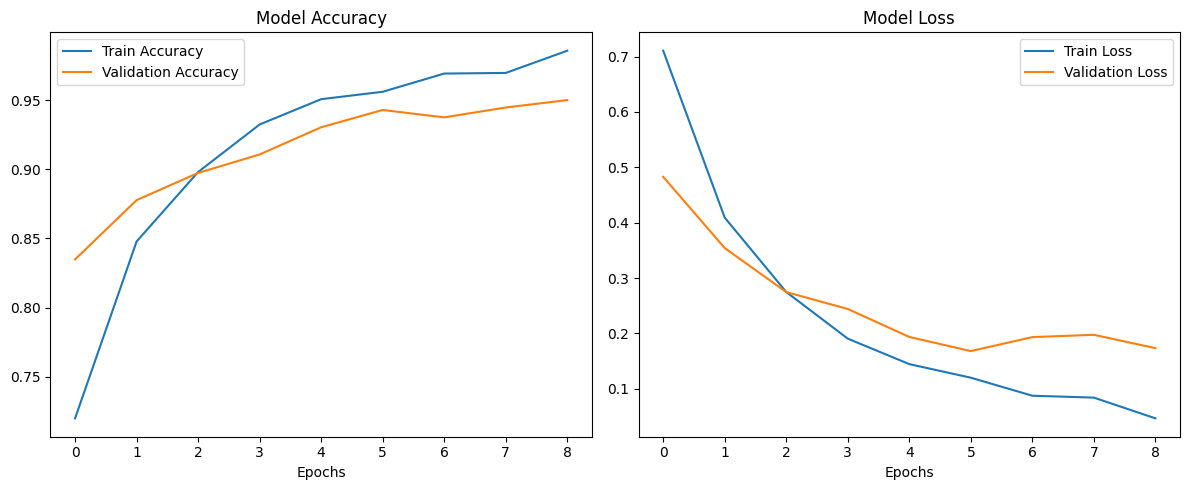

In [ ]:
#Plot Training History
plt.figure(figsize=(12, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history['accuracy'], label='Train Accuracy')
plt.plot(history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel('Epochs')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history['loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.title("Model Loss")
plt.xlabel('Epochs')
plt.legend()

plt.tight_layout()
plt.show()

### Validation set

Evaluating on Validation Set...

Classification Report:
              precision    recall  f1-score   support

      glioma       0.92      0.96      0.94       285
  meningioma       0.92      0.86      0.89       277
     notumor       0.98      0.97      0.97       289
   pituitary       0.94      0.99      0.96       269

    accuracy                           0.94      1120
   macro avg       0.94      0.94      0.94      1120
weighted avg       0.94      0.94      0.94      1120



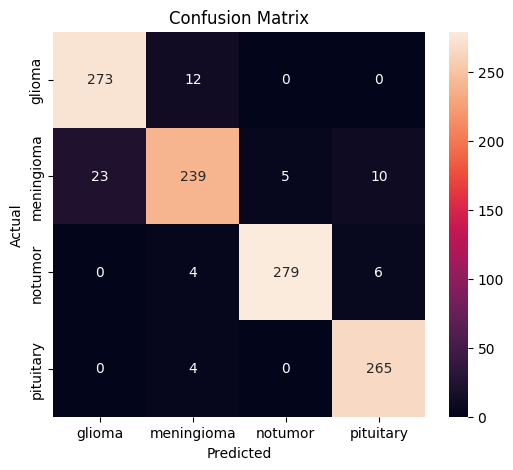

In [ ]:
#Evaluation & Predictions
model.eval()
all_preds = []
all_labels = []

print("Evaluating on Validation Set...")
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Classification Report
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=dataset.classes))

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=dataset.classes, yticklabels=dataset.classes)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Single image prediction

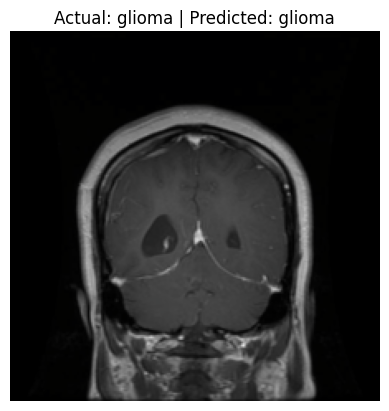

In [ ]:
# Predict on a Single Test Image
# Fetch one batch from the validation loader
test_images, test_labels = next(iter(val_loader))
single_img, single_label = test_images[0], test_labels[0]

# Add batch dimension and push to device
single_img_batch = single_img.unsqueeze(0).to(device)

with torch.no_grad():
    prediction = model(single_img_batch)
    predicted_class = torch.argmax(prediction, dim=1).item()

# Un-normalize for visualization
img_np = single_img.numpy().transpose((1, 2, 0))
mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
img_np = std * img_np + mean
img_np = np.clip(img_np, 0, 1)

plt.imshow(img_np)
plt.title(f"Actual: {dataset.classes[single_label]} | Predicted: {dataset.classes[predicted_class]}")
plt.axis("off")
plt.show()

### Test set

In [ ]:
# Define the path to the Testing folder
test_path = os.path.join(path, 'Testing')

# Apply the exact same transform used for validation
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load the dataset
test_dataset = datasets.ImageFolder(root=test_path, transform=test_transform)

# Create the DataLoader (using the M2 Pro optimized worker count)
workers = min(4, os.cpu_count() // 2)
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=workers,
    pin_memory=True
)

print(f"Total Test Images Loaded: {len(test_dataset)}")


Total Test Images Loaded: 1600


Running test set evaluation...

=== Test Set Classification Report ===
              precision    recall  f1-score   support

      glioma       0.91      0.78      0.84       400
  meningioma       0.91      0.84      0.88       400
     notumor       0.87      1.00      0.93       400
   pituitary       0.93      0.99      0.96       400

    accuracy                           0.90      1600
   macro avg       0.90      0.90      0.90      1600
weighted avg       0.90      0.90      0.90      1600



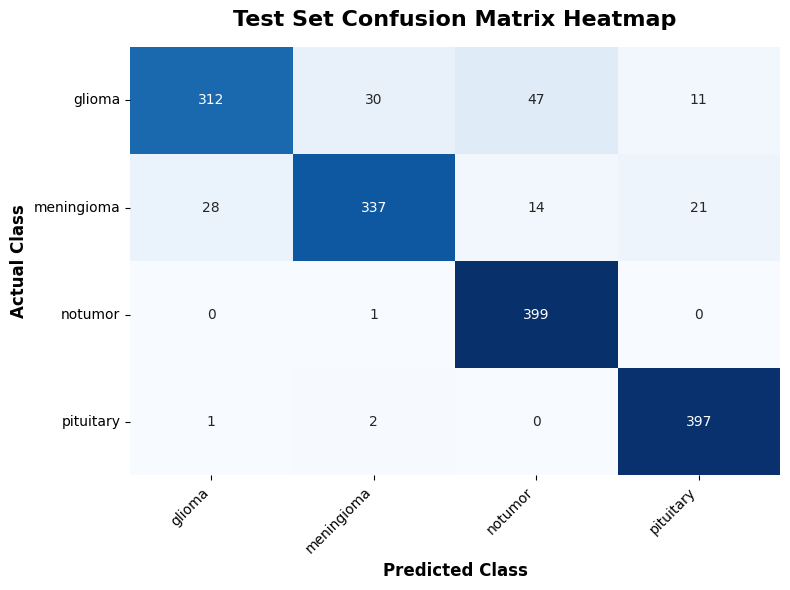

In [ ]:
model.to(device)

# Ensure the model is in evaluation mode and on the right device
model.eval()

all_preds = []
all_labels = []

print("Running test set evaluation...")

# Disable gradient tracking for faster inference and lower memory usage
with torch.no_grad():
    for inputs, labels in test_loader:
        # Move data to the same device as the model
        inputs, labels = inputs.to(device), labels.to(device)

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Generate the Classification Report
print("\n=== Test Set Classification Report ===")
print(classification_report(all_labels, all_preds, target_names=test_dataset.classes))

# Generate and Plot the Heatmap (Confusion Matrix)
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
# Using Seaborn to create a heatmap with annotations
sns.heatmap(
    cm,
    annot=True,         # Show the actual numbers in the boxes
    fmt='d',            # Format as integers
    cmap='Blues',       # A clean blue color scheme
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes,
    cbar=False          # Hide the color bar for a cleaner look
)

plt.title("Test Set Confusion Matrix Heatmap", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Predicted Class", fontsize=12, fontweight='bold')
plt.ylabel("Actual Class", fontsize=12, fontweight='bold')

# Rotate the x-axis labels slightly so the tumor names don't overlap
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


### Grad-CAM (custom CNN)

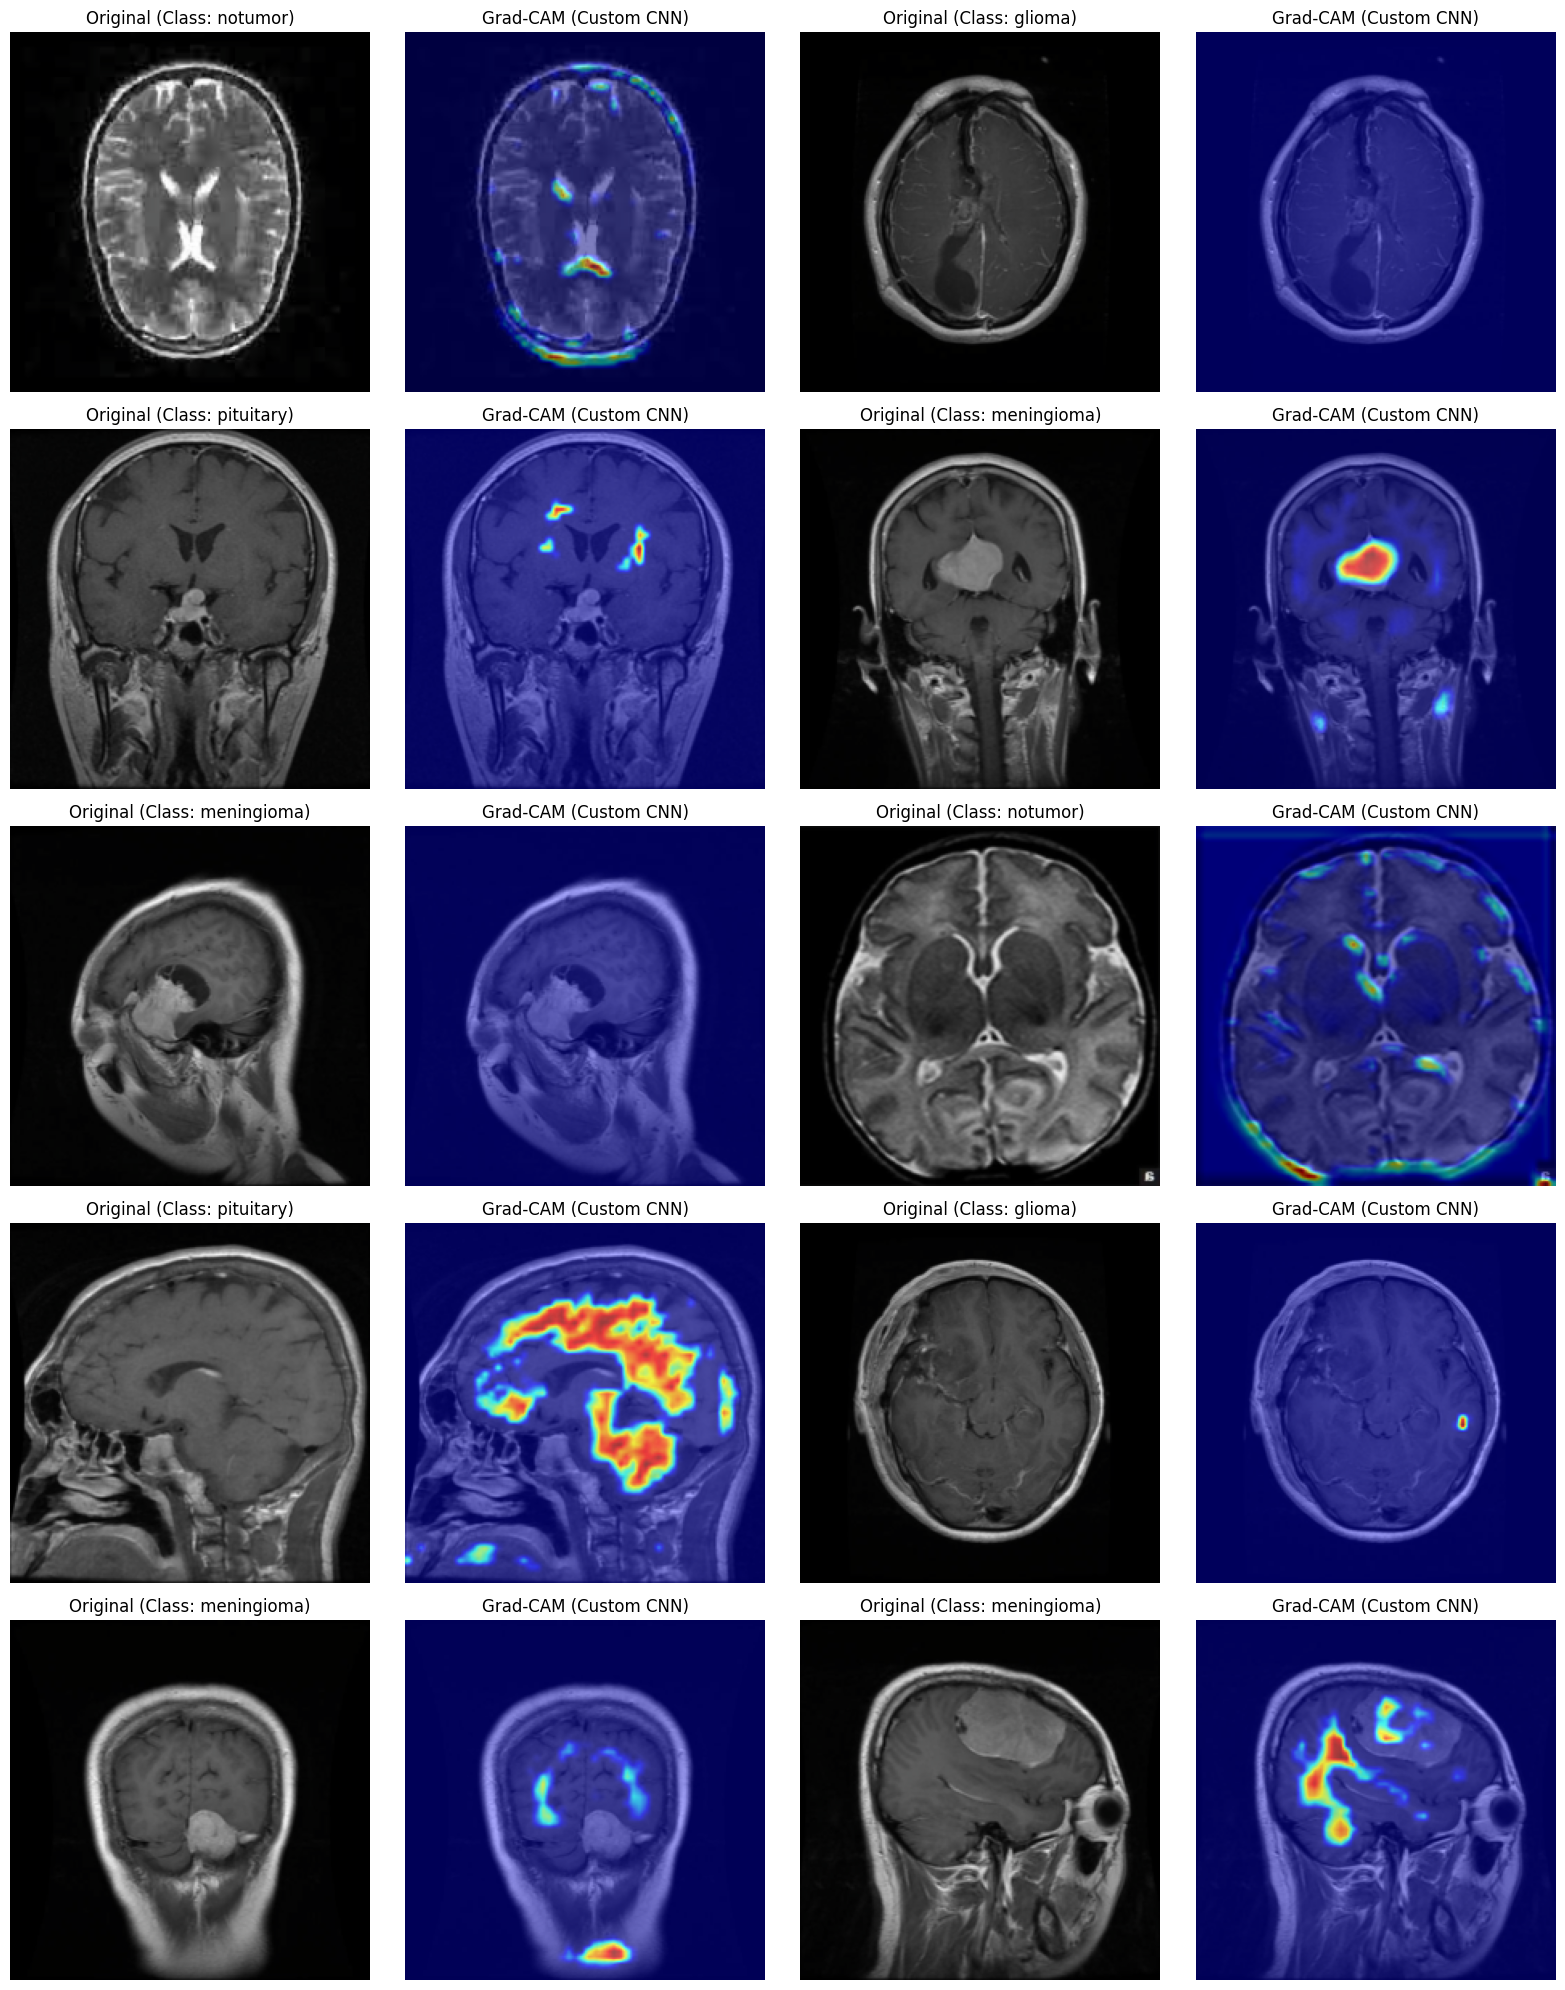

In [ ]:
import random
import math
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# For our custom BrainTumorCNN, the last convolutional layer is 'conv3'
target_layers = [model.conv3]

# Construct the CAM object
cam = GradCAM(model=model, target_layers=target_layers)

# Get a batch of validation data
val_images, val_labels = next(iter(val_loader))

# Number of images to visualize
num_images = 10
# Select random indices from the batch
indices = random.sample(range(len(val_images)), num_images)

# Set up a grid with 4 columns (2 pairs of Original + CAM per row)
pairs_per_row = 2
cols = pairs_per_row * 2
rows = math.ceil(num_images / pairs_per_row)

fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))

for i, idx in enumerate(indices):
    row = i // pairs_per_row
    col_base = (i % pairs_per_row) * 2

    # Select the image in the batch
    input_tensor = val_images[idx:idx+1].to(device)
    true_label = val_labels[idx].item()

    # Define the target category (we look at the prediction for the true class)
    targets = [ClassifierOutputTarget(true_label)]

    # Generate the CAM
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]

    # Unnormalize the original image for display
    img = val_images[idx].numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    rgb_img = std * img + mean
    rgb_img = np.clip(rgb_img, 0, 1)

    # Overlay the CAM on the image
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # Plotting
    axes[row, col_base].imshow(rgb_img)
    axes[row, col_base].set_title(f"Original (Class: {dataset.classes[true_label]})")
    axes[row, col_base].axis('off')

    axes[row, col_base+1].imshow(cam_image)
    axes[row, col_base+1].set_title(f"Grad-CAM (Custom CNN)")
    axes[row, col_base+1].axis('off')

# Hide any unused subplots if num_images isn't a perfect multiple
for i in range(num_images, rows * pairs_per_row):
    row = i // pairs_per_row
    col_base = (i % pairs_per_row) * 2
    axes[row, col_base].axis('off')
    axes[row, col_base+1].axis('off')

plt.tight_layout()
plt.show()


## Transfer learning: ResNet50, DenseNet121, EfficientNet-B0

In [ ]:
import torchvision.models as models

def get_model(model_name, num_classes):
    if model_name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        num_ftrs = model.fc.in_features
        model.fc = nn.Linear(num_ftrs, num_classes)
    elif model_name == 'densenet121':
        model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        num_ftrs = model.classifier.in_features
        model.classifier = nn.Linear(num_ftrs, num_classes)
    elif model_name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        num_ftrs = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(num_ftrs, num_classes)
    else:
        raise ValueError("Invalid model name")
    return model.to(device)

model_names = ['resnet50', 'densenet121', 'efficientnet_b0']
num_classes = len(dataset.classes)


In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler=None, num_epochs=20, patience=5):
    best_model_wts = copy.deepcopy(model.state_dict())
    best_loss = float('inf')
    epochs_no_improve = 0

    # Dictionary to track metrics for plotting
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Set model to training mode
                dataloader = train_loader
            else:
                model.eval()   # Set model to evaluate mode
                dataloader = val_loader

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data using tqdm for a progress bar.
            for inputs, labels in tqdm(dataloader, desc=phase.capitalize(), leave=False):
                inputs = inputs.to(device)
                labels = labels.to(device)

                # zero the parameter gradients
                optimizer.zero_grad()

                # forward
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # backward + optimize only if in training phase
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloader.dataset)
            epoch_acc = running_corrects.double() / len(dataloader.dataset)

            # Save metrics to history
            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item())

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # Early Stopping and Scheduler Logic
            if phase == 'val':
                if scheduler is not None:
                    scheduler.step(epoch_loss) # Reduce LR if val loss plateaus

                if epoch_loss < best_loss:
                    best_loss = epoch_loss
                    best_model_wts = copy.deepcopy(model.state_dict())
                    epochs_no_improve = 0
                else:
                    epochs_no_improve += 1

        print()

        if epochs_no_improve >= patience:
            print("Early stopping triggered! Restoring best weights.")
            break

    print(f'Training complete. Best Val Loss: {best_loss:.4f}')
    # load best model weights
    model.load_state_dict(best_model_wts)
    return model, history, best_loss

# Train all models and pick the best
best_overall_loss = float('inf')
best_overall_model_name = ""
trained_model = None
all_histories = {}

for model_name in model_names:
    print(f"\n=========================================")
    print(f"Training Model: {model_name}")
    print(f"=========================================")

    current_model = get_model(model_name, num_classes)
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(current_model.parameters(), lr=1e-4)

    # Initialize the Learning Rate Scheduler
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)

    # Run the training loop with Early Stopping and Scheduler
    current_model, model_history, best_loss = train_model(
        current_model, train_loader, val_loader, criterion, optimizer,
        scheduler=scheduler, num_epochs=20, patience=5
    )

    all_histories[model_name] = model_history

    if best_loss < best_overall_loss:
        best_overall_loss = best_loss
        best_overall_model_name = model_name
        trained_model = copy.deepcopy(current_model)

print(f"\n=========================================")
print(f"🏆 Best Model Selected: {best_overall_model_name} with Val Loss: {best_overall_loss:.4f}")
print(f"=========================================")

# Set 'history' to the best model's history so plotting cells work unmodified
history = all_histories[best_overall_model_name]



Training Model: resnet50
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 240MB/s]


Epoch 1/20
----------


Train Loss: 0.2792 Acc: 0.8993


Val Loss: 0.1226 Acc: 0.9536

Epoch 2/20
----------


Train Loss: 0.0986 Acc: 0.9658


... (91 outputs left out)

Train Loss: 0.0209 Acc: 0.9944


Val Loss: 0.0436 Acc: 0.9884

Epoch 14/20
----------


Train Loss: 0.0123 Acc: 0.9958


Val Loss: 0.0413 Acc: 0.9920

Early stopping triggered! Restoring best weights.
Training complete. Best Val Loss: 0.0311

🏆 Best Model Selected: densenet121 with Val Loss: 0.0198


### Training curves (best model)

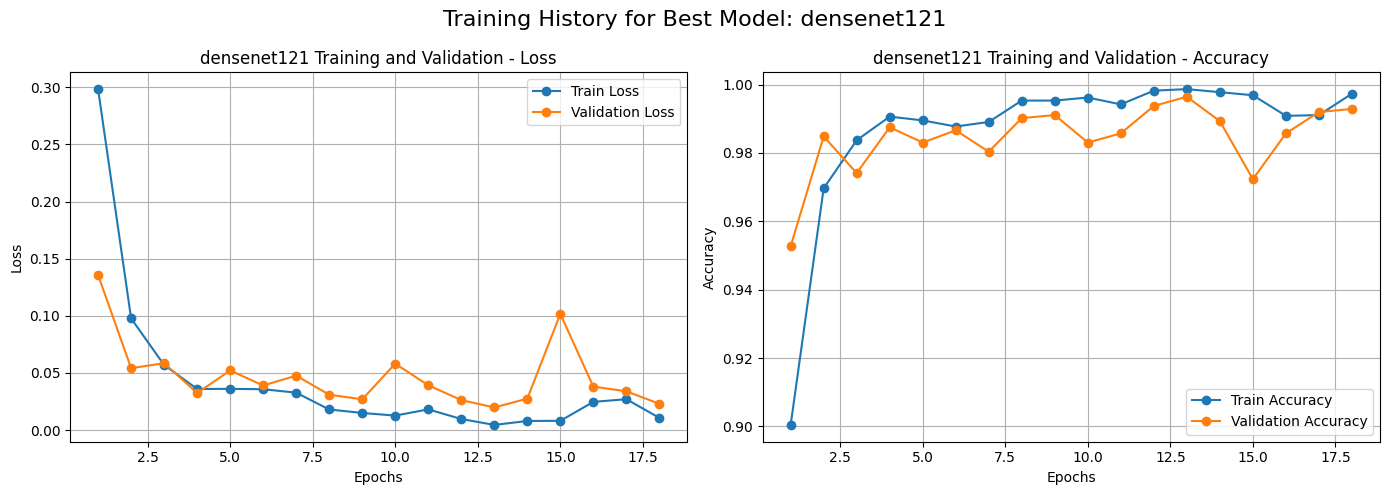

In [ ]:
# --- Plotting Loss and Accuracy ---
epochs_run = len(history['train_loss'])
epochs_range = range(1, epochs_run + 1)

plt.figure(figsize=(14, 5))
plt.suptitle(f"Training History for Best Model: {best_overall_model_name}", fontsize=16)

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', marker='o')
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', marker='o')
plt.title(f'{best_overall_model_name} Training and Validation - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Train Accuracy', marker='o')
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', marker='o')
plt.title(f'{best_overall_model_name} Training and Validation - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Test set (best model)

In [ ]:
# --- Evaluate on the Unseen Testing Folder ---
print(f"\n--- Final Evaluation on Unseen Testing Set ({best_overall_model_name}) ---")

trained_model.eval()
test_loss = 0.0
test_corrects = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Testing", leave=False):
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = trained_model(inputs)
        loss = criterion(outputs, labels)
        _, preds = torch.max(outputs, 1)

        test_loss += loss.item() * inputs.size(0)
        test_corrects += torch.sum(preds == labels.data)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = test_corrects.double() / len(test_dataset)
test_epoch_loss = test_loss / len(test_dataset)
print(f"Total unseen testing images: {len(test_dataset)}")
print(f"Final Testing Loss: {test_epoch_loss:.4f} | Testing Acc: {test_acc:.4f}\n")

# --- Classification Report ---
print(f"--- Classification Report ({best_overall_model_name}) ---")
print(classification_report(all_labels, all_preds, target_names=test_dataset.classes))



--- Final Evaluation on Unseen Testing Set (densenet121) ---


Total unseen testing images: 1600
Final Testing Loss: 0.2984 | Testing Acc: 0.9550

--- Classification Report (densenet121) ---
              precision    recall  f1-score   support

      glioma       1.00      0.83      0.91       400
  meningioma       0.89      0.99      0.94       400
     notumor       0.95      1.00      0.97       400
   pituitary       1.00      1.00      1.00       400

    accuracy                           0.95      1600
   macro avg       0.96      0.95      0.95      1600
weighted avg       0.96      0.95      0.95      1600



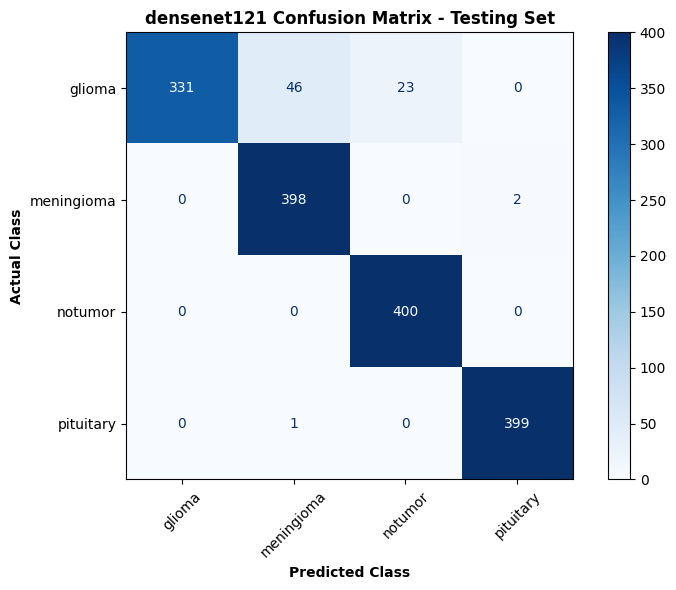

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Calculate confusion matrix using the true labels and predictions from the testing phase
cm = confusion_matrix(all_labels, all_preds)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=test_dataset.classes)

# We use a blue color map and rotate the x-axis labels for better readability
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title(f'{best_overall_model_name} Confusion Matrix - Testing Set', fontweight='bold')
plt.xlabel("Predicted Class", fontweight='bold')
plt.ylabel("Actual Class", fontweight='bold')
plt.tight_layout()
plt.show()


### Grad-CAM (best model)

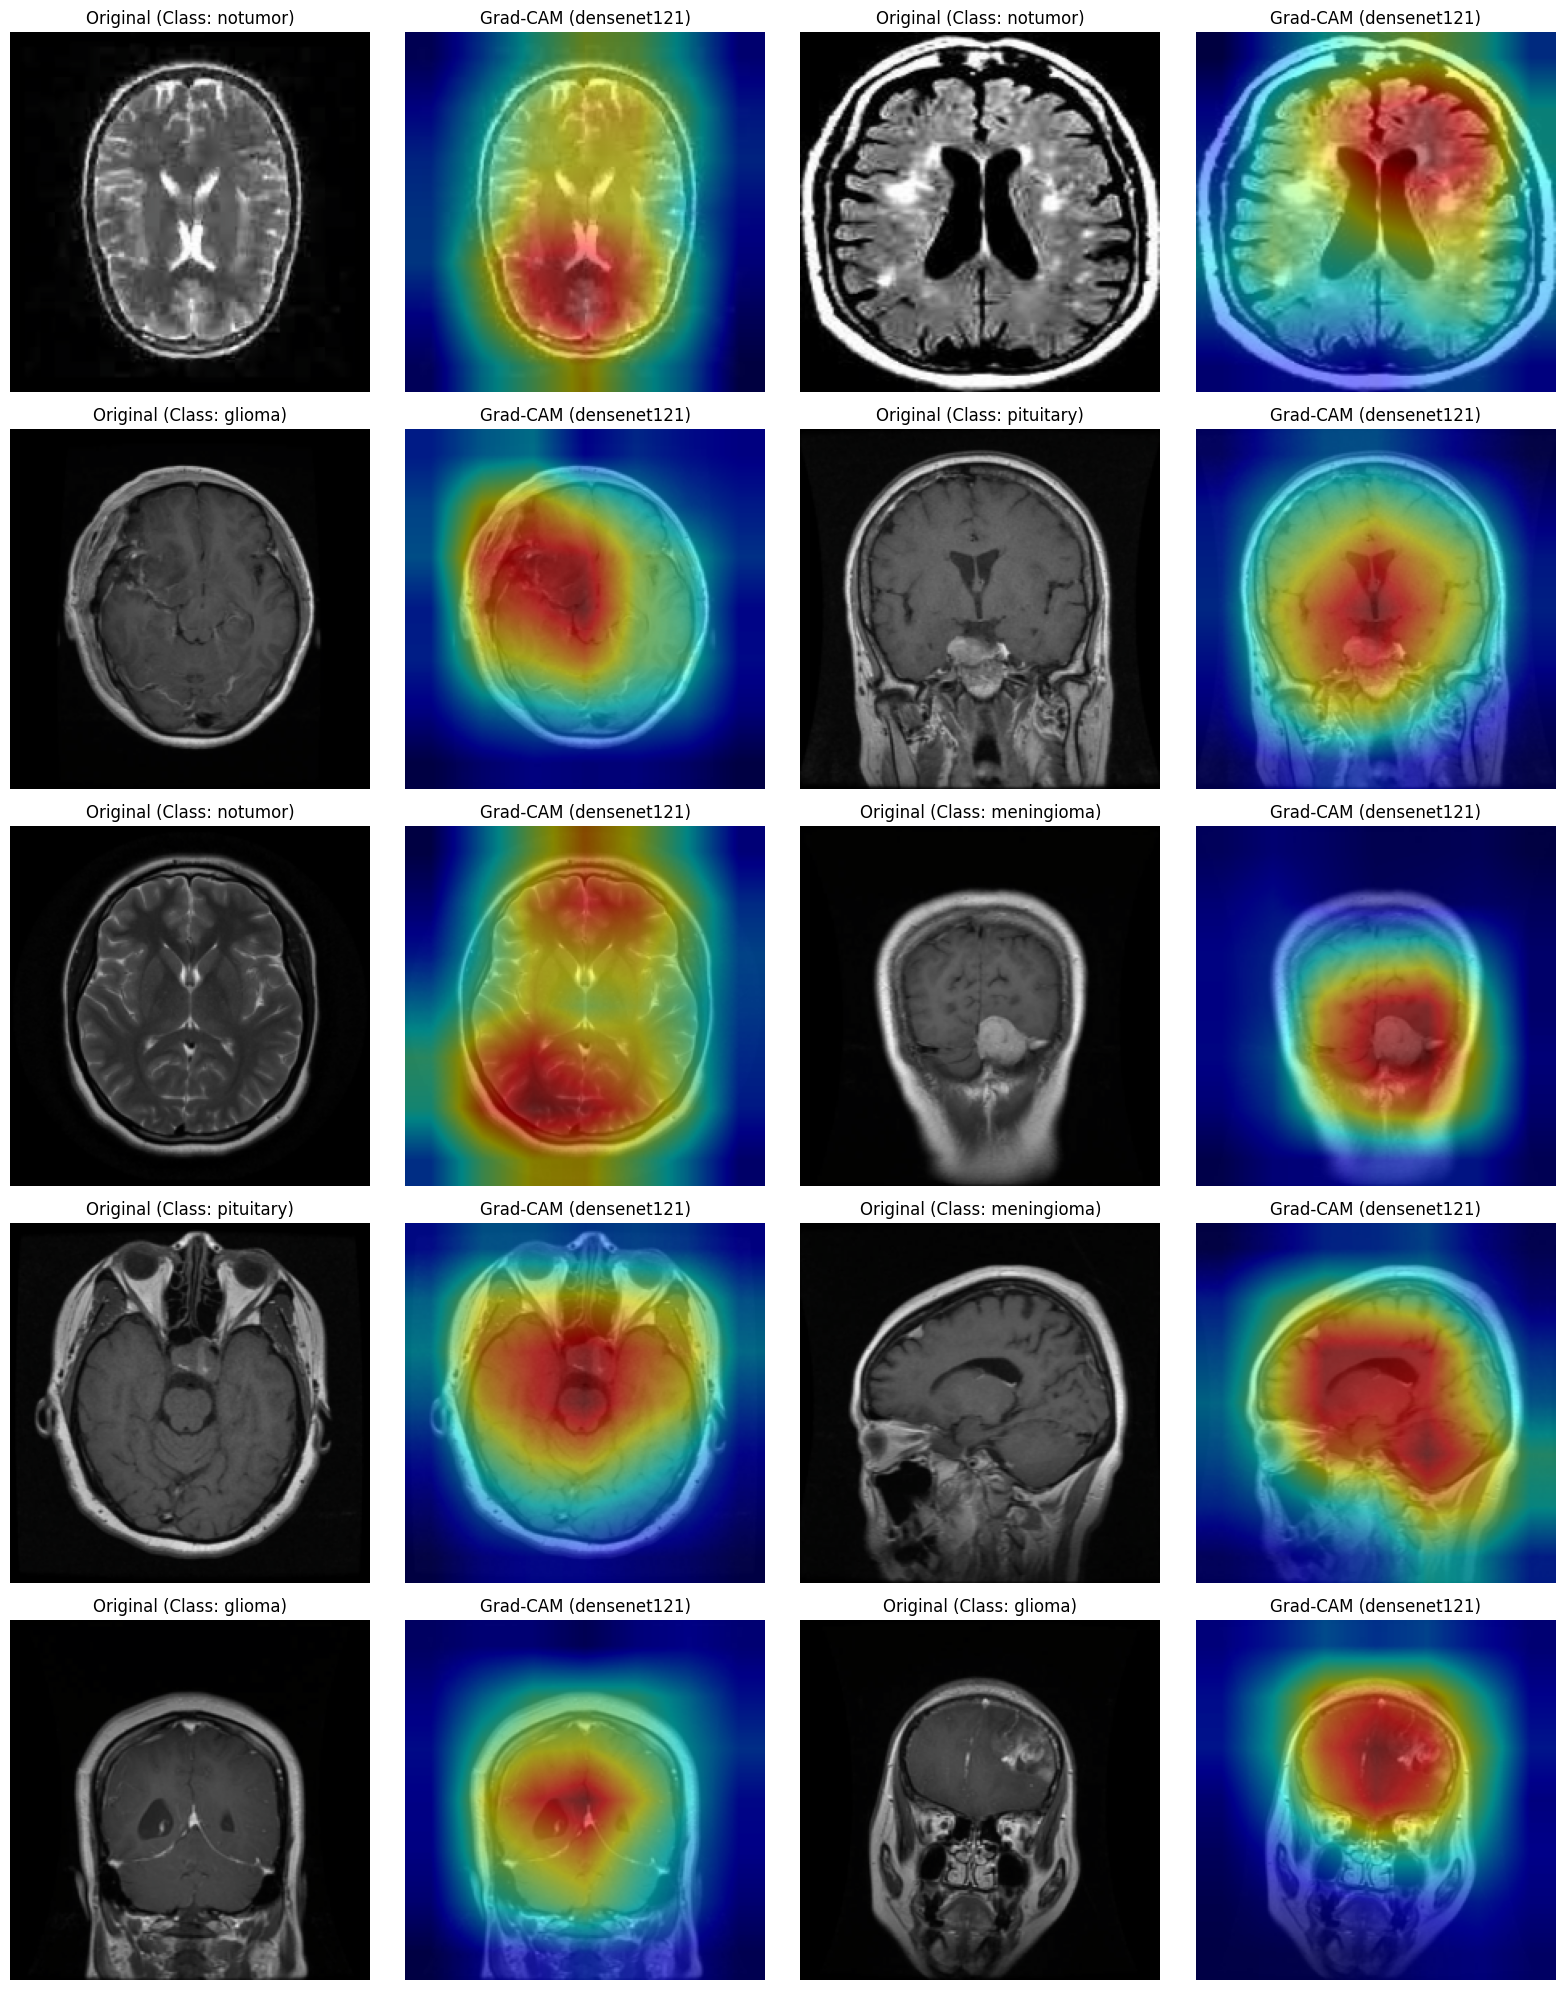

In [ ]:
# Dynamically choose the target layer based on the best model architecture
if best_overall_model_name == 'resnet50':
    target_layers = [trained_model.layer4[-1]]
elif best_overall_model_name == 'densenet121':
    target_layers = [trained_model.features[-1]]
elif best_overall_model_name == 'efficientnet_b0':
    target_layers = [trained_model.features[-1]]
else:
    target_layers = [trained_model.layer4[-1]]

# Construct the CAM object
cam = GradCAM(model=trained_model, target_layers=target_layers)

# Get a batch of validation data
val_images, val_labels = next(iter(val_loader))

# Number of images to visualize
num_images = 10
# Select random indices from the batch
indices = random.sample(range(len(val_images)), num_images)

# Set up a grid with 4 columns (2 pairs of Original + CAM per row)
pairs_per_row = 2
cols = pairs_per_row * 2
rows = math.ceil(num_images / pairs_per_row)

fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))

for i, idx in enumerate(indices):
    row = i // pairs_per_row
    col_base = (i % pairs_per_row) * 2

    # Select the image in the batch
    input_tensor = val_images[idx:idx+1].to(device)
    true_label = val_labels[idx].item()

    # Define the target category (we look at the prediction for the true class)
    targets = [ClassifierOutputTarget(true_label)]

    # Generate the CAM
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]

    # Unnormalize the original image for display
    img = val_images[idx].numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    rgb_img = std * img + mean
    rgb_img = np.clip(rgb_img, 0, 1)

    # Overlay the CAM on the image
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # Plotting
    axes[row, col_base].imshow(rgb_img)
    axes[row, col_base].set_title(f"Original (Class: {dataset.classes[true_label]})")
    axes[row, col_base].axis('off')

    axes[row, col_base+1].imshow(cam_image)
    axes[row, col_base+1].set_title(f"Grad-CAM ({best_overall_model_name})")
    axes[row, col_base+1].axis('off')

# Hide any unused subplots if num_images isn't a perfect multiple
for i in range(num_images, rows * pairs_per_row):
    row = i // pairs_per_row
    col_base = (i % pairs_per_row) * 2
    axes[row, col_base].axis('off')
    axes[row, col_base+1].axis('off')

plt.tight_layout()
plt.show()


## Saving the models

In [ ]:
import torch

# 1. Save the Custom CNN
# Saving the state_dict (weights only) is the recommended way in PyTorch
custom_cnn_path = 'custom_cnn_weights.pth'
torch.save(model.state_dict(), custom_cnn_path)
print(f"✅ Custom CNN weights saved to: {custom_cnn_path}")

# 2. Save the Best Transfer Learning Model (DenseNet121)
best_model_path = f'{best_overall_model_name}_weights.pth'
torch.save(trained_model.state_dict(), best_model_path)
print(f"✅ Best Transfer Learning ({best_overall_model_name}) weights saved to: {best_model_path}")

# save the ENTIRE model (architecture + weights) into one file:
torch.save(model, 'custom_cnn_complete.pth')
torch.save(trained_model, f'{best_overall_model_name}_complete.pth')

✅ Custom CNN weights saved to: custom_cnn_weights.pth
✅ Best Transfer Learning (densenet121) weights saved to: densenet121_weights.pth


### ONNX export

In [ ]:
# Create a dummy input tensor matching the input shape of the models (1 batch, 3 channels, 224x224)
dummy_input = torch.randn(1, 3, 224, 224).to(device)

# 1. Export Custom CNN to ONNX
onnx_custom_path = "custom_cnn.onnx"
torch.onnx.export(
    model,
    dummy_input,
    onnx_custom_path,
    export_params=True,
    opset_version=11,
    input_names=['input'],
    output_names=['output']
)
print(f"✅ Custom CNN exported to ONNX: {onnx_custom_path}")

# 2. Export Best Transfer Learning Model to ONNX
onnx_best_path = f"{best_overall_model_name}.onnx"
torch.onnx.export(
    trained_model,
    dummy_input,
    onnx_best_path,
    export_params=True,
    opset_version=11,
    input_names=['input'],
    output_names=['output']
)
print(f"✅ Best Model ({best_overall_model_name}) exported to ONNX: {onnx_best_path}")

✅ Custom CNN exported to ONNX: custom_cnn.onnx


✅ Best Model (densenet121) exported to ONNX: densenet121.onnx
